# Machine Learning Fundamentals
## Unit 03 — Underfitting, Overfitting & Model Complexity

**Stage 2: Machine Learning | Beginner level | B2 English**  
**Business scenario:** Melbourne house-price estimation  
**Environment:** Google Colab / Jupyter Notebook  
**Libraries:** Pandas, Matplotlib, scikit-learn

---

## Why this lesson matters

In the previous unit, you learned how to evaluate a model using validation data. Now we will use that skill to answer a new question:

**How complex should our model be?**

A model that is too simple may miss important patterns. A model that is too complex may learn details that do not generalize to new houses. In this lesson, you will compare Decision Trees with different sizes and use validation MAE to understand the trade-off.

### Dataset and continuity

We continue using the provided `melb_data.csv` dataset and the same five numeric features as in the previous lessons:

- `Rooms`
- `Bathroom`
- `Landsize`
- `Lattitude`
- `Longtitude`

The target is `Price`. The dataset contains historical Melbourne housing records; results are for learning and should not be treated as current property valuations.

> **Instructor note:** This notebook builds directly on Model Validation. Students should already understand `X`, `y`, training/validation splits, `fit()`, `predict()`, and MAE.

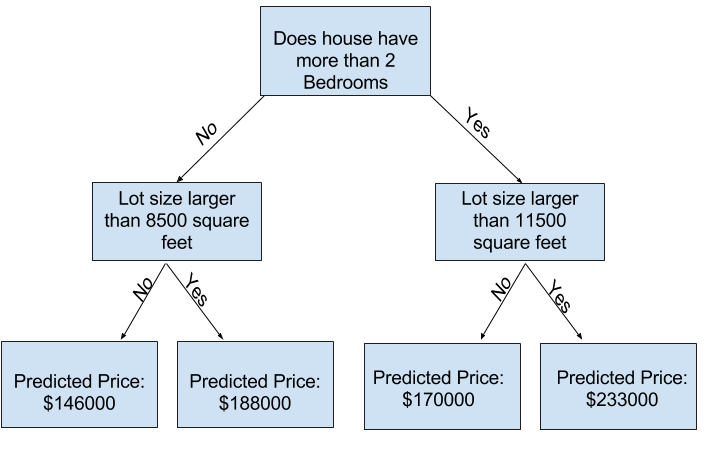

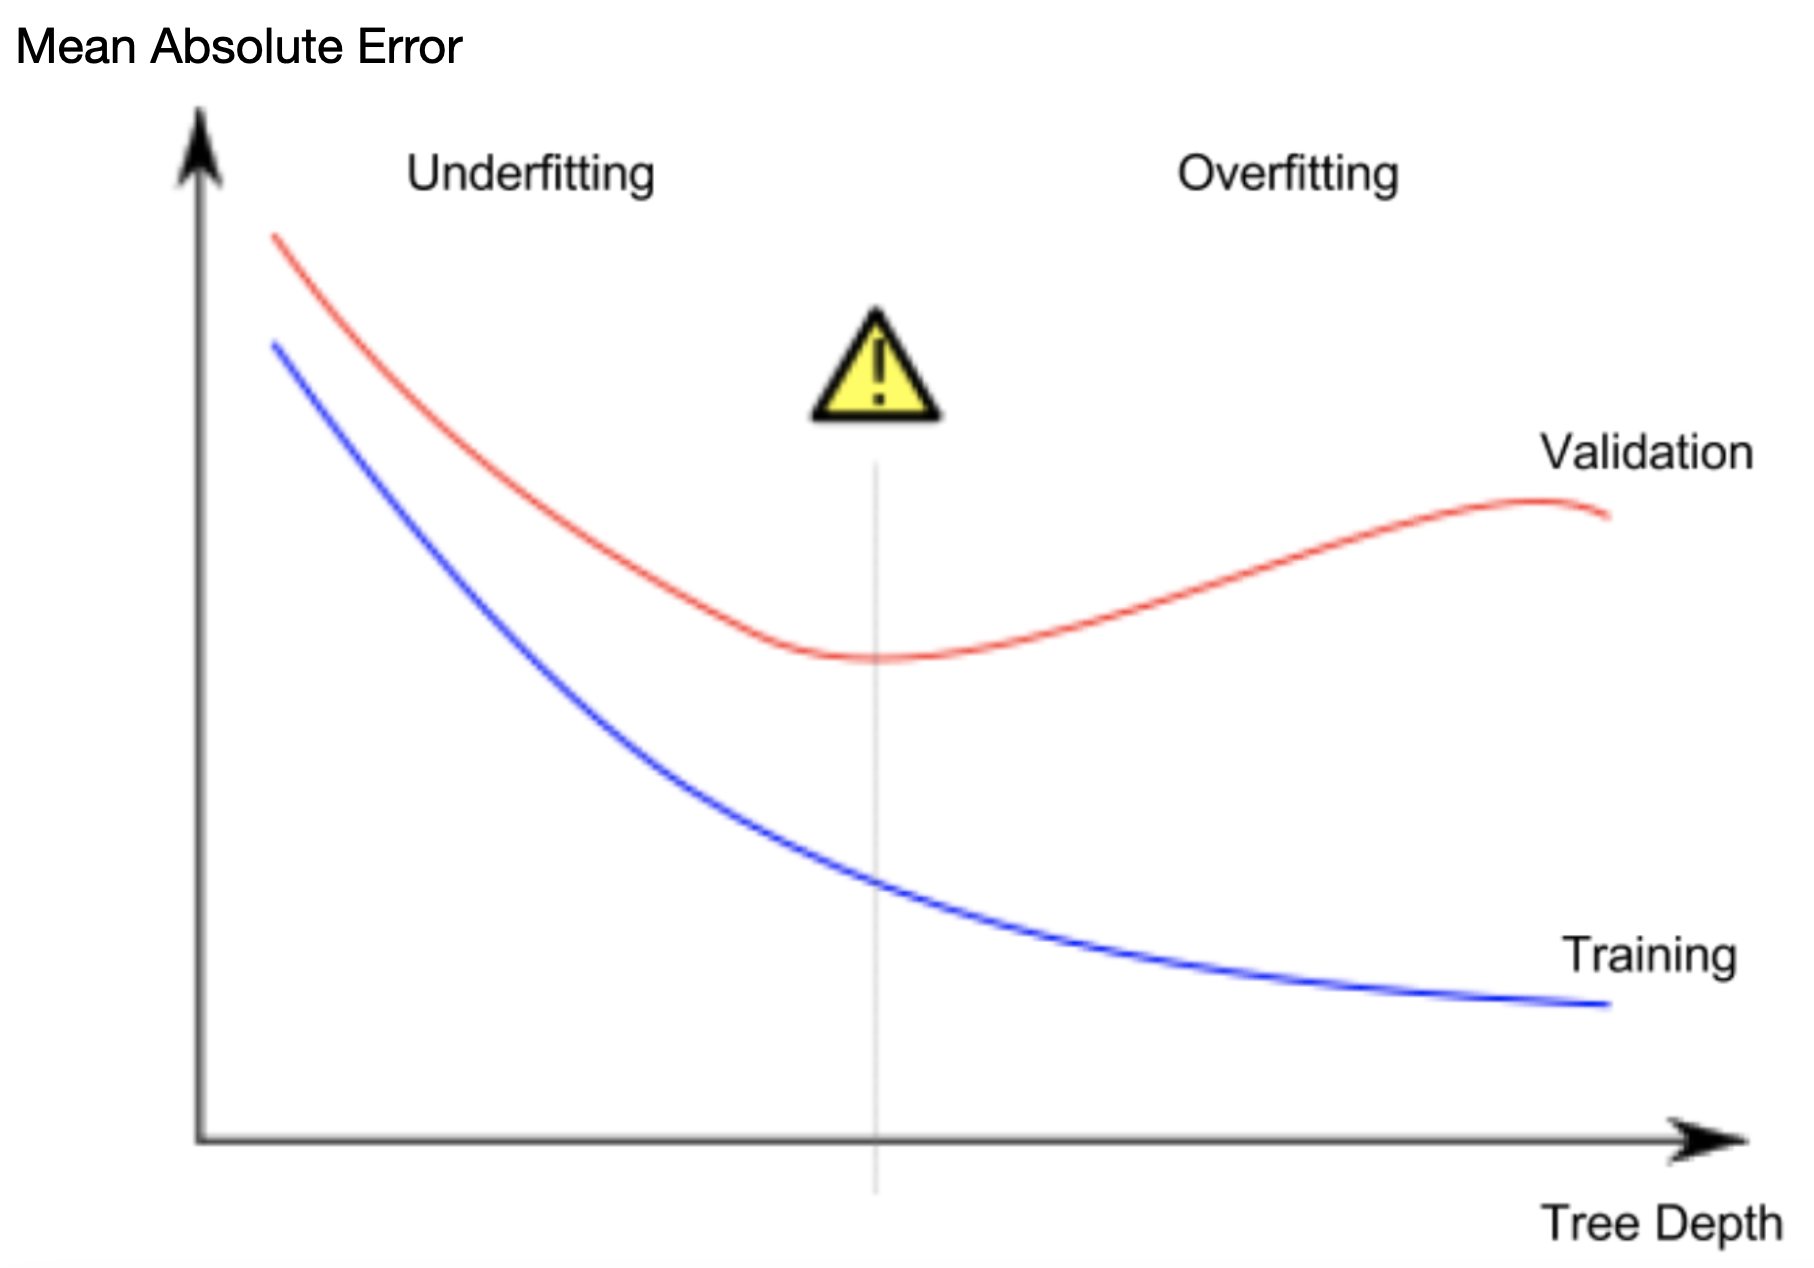

## Learning outcomes

By the end of this notebook, you should be able to:

1. Explain underfitting and overfitting in plain language.
2. Describe how tree complexity changes the model's behavior.
3. Explain the role of leaf nodes in a Decision Tree Regressor.
4. Compare candidate models using validation MAE.
5. Use `max_leaf_nodes` to control tree complexity.
6. Select the best candidate from a defined set of options.
7. Explain why the best validation score is not a guarantee of future performance.

## Notebook roadmap

1. Model complexity and leaf nodes
2. Underfitting vs. overfitting
3. Prepare the dataset
4. Compare tree sizes
5. Visualize the validation results
6. Select a candidate and discuss limitations
7. Practical challenge and readiness check

**Study routine:** Read the explanation, run the code, inspect the output, and answer the reflection questions before moving on.

# 1. Model Complexity and Leaf Nodes

## 1.1 What is a leaf node?

A **leaf** is an endpoint of a Decision Tree. It contains the prediction made for observations that reach that part of the tree.

Allowing more leaves gives a tree more opportunities to divide the data into smaller groups. This can help the model capture useful patterns. However, if leaves contain very few training examples, the model may also learn noise or unusual details that do not repeat in new data.

In scikit-learn, `max_leaf_nodes` sets an upper limit on the number of leaves. It is one way to control tree complexity.

## 1.2 Underfitting vs. overfitting

| Concept | What happens? | Common error pattern |
|---|---|---|
| **Underfitting** | The model is too simple to capture important patterns. | Training error and validation error are both relatively high. |
| **Good fit** | The model captures useful patterns and generalizes reasonably well. | Validation error is relatively low. |
| **Overfitting** | The model learns details or noise that do not generalize well. | Training error is very low, while validation error is much higher. |

These patterns are useful clues, not absolute rules. Scores also depend on the dataset, the features, the split, and the metric.

## 1.3 The model-complexity trade-off

As model complexity increases, training error often decreases because the model can fit the training examples more closely. Validation error may first decrease, then stop improving or increase when the model becomes too complex.

The goal is not to build the largest possible tree. The goal is to find a model that captures useful patterns and performs well on unseen data.

### Check your understanding

1. What is a leaf node?
2. What might happen if a tree has too few leaves?
3. What might happen if a tree has too many leaves?
4. Why should we use validation error—not training error alone—to compare tree sizes?

# 2. Prepare the Dataset

We will repeat the key preparation steps so this notebook can run independently. In Google Colab, upload `melb_data.csv` to the session before running the next cell. If the file is in the same folder as the notebook, the path below works as written.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

melbourne_file_path = "melb_data.csv"
melbourne_data = pd.read_csv(melbourne_file_path)

feature_names = ["Rooms", "Bathroom", "Landsize", "Lattitude", "Longtitude"]
target_name = "Price"
required_columns = feature_names + [target_name]

print("Dataset shape:", melbourne_data.shape)
display(melbourne_data.head())

## 2.1 Select features and target

We select the same features used in the earlier notebooks. Rows with missing values in these selected columns are removed for this introductory example.

**Important limitation:** Dropping rows is a simple teaching choice, not a universal best practice. Real projects should examine missingness and choose a suitable strategy.

In [ ]:
model_data = melbourne_data[required_columns].dropna().copy()

X = model_data[feature_names]
y = model_data[target_name]

print(f"Rows retained: {len(model_data):,}")
print(f"Rows removed due to missing selected values: {len(melbourne_data) - len(model_data):,}")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

## 2.2 Create training and validation sets

We use the same split approach as in the previous lesson. The model learns from the training set. We use the validation set to compare different values of `max_leaf_nodes`.

`random_state=0` makes the split reproducible for this dataset and setup.

In [ ]:
train_X, val_X, train_y, val_y = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=0
)

print(f"Training rows: {len(train_X):,}")
print(f"Validation rows: {len(val_X):,}")

# 3. Compare Different Tree Sizes

## 3.1 Build a reusable evaluation function

We will train a Decision Tree for each candidate leaf count and calculate its validation MAE.

A function helps us avoid repeating the same steps manually. It also makes the comparison easier to read and less likely to contain inconsistent code.

In [ ]:
def get_mae(max_leaf_nodes, train_X, val_X, train_y, val_y):
    """Train a Decision Tree and return its validation MAE."""
    model = DecisionTreeRegressor(
        max_leaf_nodes=max_leaf_nodes,
        random_state=0
    )
    model.fit(train_X, train_y)
    validation_predictions = model.predict(val_X)
    return mean_absolute_error(val_y, validation_predictions)

### What does the function do?

1. Creates a Decision Tree with the selected maximum number of leaves.
2. Fits the model using training data only.
3. Predicts prices for validation features.
4. Compares predictions with actual validation prices using MAE.
5. Returns the validation MAE.

The same split and evaluation metric are used for every candidate, making the results more comparable.

## 3.2 Evaluate a range of candidate leaf counts

We will compare a small, defined set of values. These candidates are examples for teaching; they are not guaranteed to contain the best possible setting.

In [ ]:
candidate_max_leaf_nodes = [5, 20, 50, 100, 500, 1000, 5000]

results = []
for leaf_count in candidate_max_leaf_nodes:
    validation_mae = get_mae(
        leaf_count,
        train_X,
        val_X,
        train_y,
        val_y
    )
    results.append({
        "max_leaf_nodes": leaf_count,
        "validation_MAE_AUD": validation_mae
    })

results_df = pd.DataFrame(results).sort_values("max_leaf_nodes")
display(results_df.style.format({"validation_MAE_AUD": "AUD {:,.0f}"}))

## 3.3 Visualize validation MAE

The chart makes it easier to see how validation error changes as the tree is allowed to grow. Lower MAE is better for this comparison.

Do not assume the curve must always decrease and then increase. Its shape depends on the data and the candidate settings.

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    results_df["max_leaf_nodes"],
    results_df["validation_MAE_AUD"],
    marker="o"
)
ax.set_xscale("log")
ax.set_title("Validation MAE by Decision Tree Size")
ax.set_xlabel("Maximum number of leaf nodes (log scale)")
ax.set_ylabel("Validation MAE (AUD)")
ax.grid(True, which="both", alpha=0.25)
plt.tight_layout()
plt.show()

## 3.4 Select the best candidate from this comparison

We can use `idxmin()` to find the row with the lowest validation MAE among the candidates we tested.

**Be precise in your conclusion:** This identifies the best candidate in our tested list on this particular validation split. It does not prove that it is the best possible model or that it will perform best on every future sample.

In [ ]:
best_row = results_df.loc[results_df["validation_MAE_AUD"].idxmin()]

best_leaf_count = int(best_row["max_leaf_nodes"])
best_validation_mae = float(best_row["validation_MAE_AUD"])

print(f"Best candidate in this search: max_leaf_nodes={best_leaf_count}")
print(f"Validation MAE: AUD {best_validation_mae:,.0f}")

## 3.5 Compare training and validation error for the candidates

Training MAE usually decreases as the tree is allowed to become more complex. Validation MAE helps us see whether that extra complexity also improves predictions on held-out data.

We calculate both metrics for each candidate to make the difference visible.

In [ ]:
complexity_results = []

for leaf_count in candidate_max_leaf_nodes:
    candidate_model = DecisionTreeRegressor(
        max_leaf_nodes=leaf_count,
        random_state=0
    )
    candidate_model.fit(train_X, train_y)

    train_predictions = candidate_model.predict(train_X)
    validation_predictions = candidate_model.predict(val_X)

    complexity_results.append({
        "max_leaf_nodes": leaf_count,
        "training_MAE_AUD": mean_absolute_error(train_y, train_predictions),
        "validation_MAE_AUD": mean_absolute_error(val_y, validation_predictions)
    })

complexity_df = pd.DataFrame(complexity_results)
display(complexity_df.style.format({
    "training_MAE_AUD": "AUD {:,.0f}",
    "validation_MAE_AUD": "AUD {:,.0f}"
}))

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    complexity_df["max_leaf_nodes"],
    complexity_df["training_MAE_AUD"],
    marker="o",
    label="Training MAE"
)
ax.plot(
    complexity_df["max_leaf_nodes"],
    complexity_df["validation_MAE_AUD"],
    marker="o",
    label="Validation MAE"
)
ax.set_xscale("log")
ax.set_title("Training vs Validation MAE")
ax.set_xlabel("Maximum number of leaf nodes (log scale)")
ax.set_ylabel("MAE (AUD)")
ax.legend()
ax.grid(True, which="both", alpha=0.25)
plt.tight_layout()
plt.show()

### Interpret the results

Use the table and charts to answer:

- Which candidate has the lowest validation MAE?
- Does training MAE change in the same way as validation MAE?
- At what point, if any, does increasing the number of leaves stop improving validation performance?
- Which result would you report, and what limitation would you mention?

A widening gap between training and validation errors can be a warning sign of overfitting. The exact point depends on the data and split.

# 4. A Responsible Model-Selection Workflow

The best candidate was selected using the validation set. That is a normal part of model development, but it means the validation score has influenced our choice.

For a more reliable estimate of final performance, a professional workflow keeps a separate **test set** untouched until model choices are complete. Another option is cross-validation within the training data for model selection, followed by a final test evaluation.

For this introductory unit, we will not build a full tuning pipeline yet. The important lesson is to avoid repeatedly changing the model based on the final test score.

# 5. Practical Activity

Complete the official Kaggle lesson and exercise:

- [Kaggle — Underfitting and Overfitting](https://www.kaggle.com/code/yazeedalasmar/exercise-underfitting-and-overfitting)

## Student challenge

1. Add two more values to `candidate_max_leaf_nodes`.
2. Rerun the comparison.
3. Identify the candidate with the lowest validation MAE.
4. Explain why the lowest training MAE is not necessarily the best choice.
5. Write a short recommendation that includes one result, one limitation, and one next step.

## Instructor discussion prompt

Ask learners to imagine that the model will be used to support a real business decision. What evidence would they need before trusting its predictions? Encourage answers about test data, cross-validation, data quality, changing market conditions, and the cost of prediction errors.